In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
housing = fetch_california_housing()

X = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y = pd.Series(
    housing.target,
    name="MedHouseVal"
)

# Display dataset
print("Dataset Shape:", X.shape)
print("\nFirst Five Rows:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Dataset Shape: (20640, 8)

First Five Rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Target Variable:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [ ]:
# Check missing values
print("Missing Values:")
print(X.isnull().sum())

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Missing Values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64
Training Samples: 16512
Testing Samples: 4128


In [ ]:
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Regression Completed")

Linear Regression Completed


In [ ]:
decision_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=15
)

decision_model.fit(X_train, y_train)

decision_pred = decision_model.predict(X_test)

print("Decision Tree Regression Completed")

Decision Tree Regression Completed


In [ ]:
random_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_model.fit(X_train, y_train)

random_pred = random_model.predict(X_test)

print("Random Forest Regression Completed")

Random Forest Regression Completed


In [ ]:
neural_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=300,
        random_state=42,
        early_stopping=True
    )
)

neural_model.fit(X_train, y_train)

neural_pred = neural_model.predict(X_test)

print("Neural Network Regression Completed")

Neural Network Regression Completed


In [ ]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective='reg:squarederror',
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

print("XGBoost Regression Completed")

XGBoost Regression Completed


In [ ]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(
        n_neighbors=5
    )
)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN Regression Completed")

KNN Regression Completed


In [ ]:
# Store all predictions
predictions = {
    "Linear Regression": linear_pred,
    "Decision Tree": decision_pred,
    "Random Forest": random_pred,
    "Neural Network": neural_pred,
    "XGBoost": xgb_pred,
    "KNN": knn_pred
}

# Calculate evaluation metrics
results = []

for name, pred in predictions.items():

    mae = mean_absolute_error(y_test, pred)

    mse = mean_squared_error(y_test, pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, pred)

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Comparative table
results_df = pd.DataFrame(results)

print("\nComparative Performance:")
print(results_df.round(4).to_string(index=False))


Comparative Performance:
        Algorithm    MAE    MSE   RMSE  R2 Score
Linear Regression 0.5332 0.5559 0.7456    0.5758
    Decision Tree 0.4375 0.4639 0.6811    0.6460
    Random Forest 0.3275 0.2554 0.5053    0.8051
   Neural Network 0.3533 0.2745 0.5239    0.7905
          XGBoost 0.3156 0.2245 0.4739    0.8287
              KNN 0.4462 0.4324 0.6576    0.6700


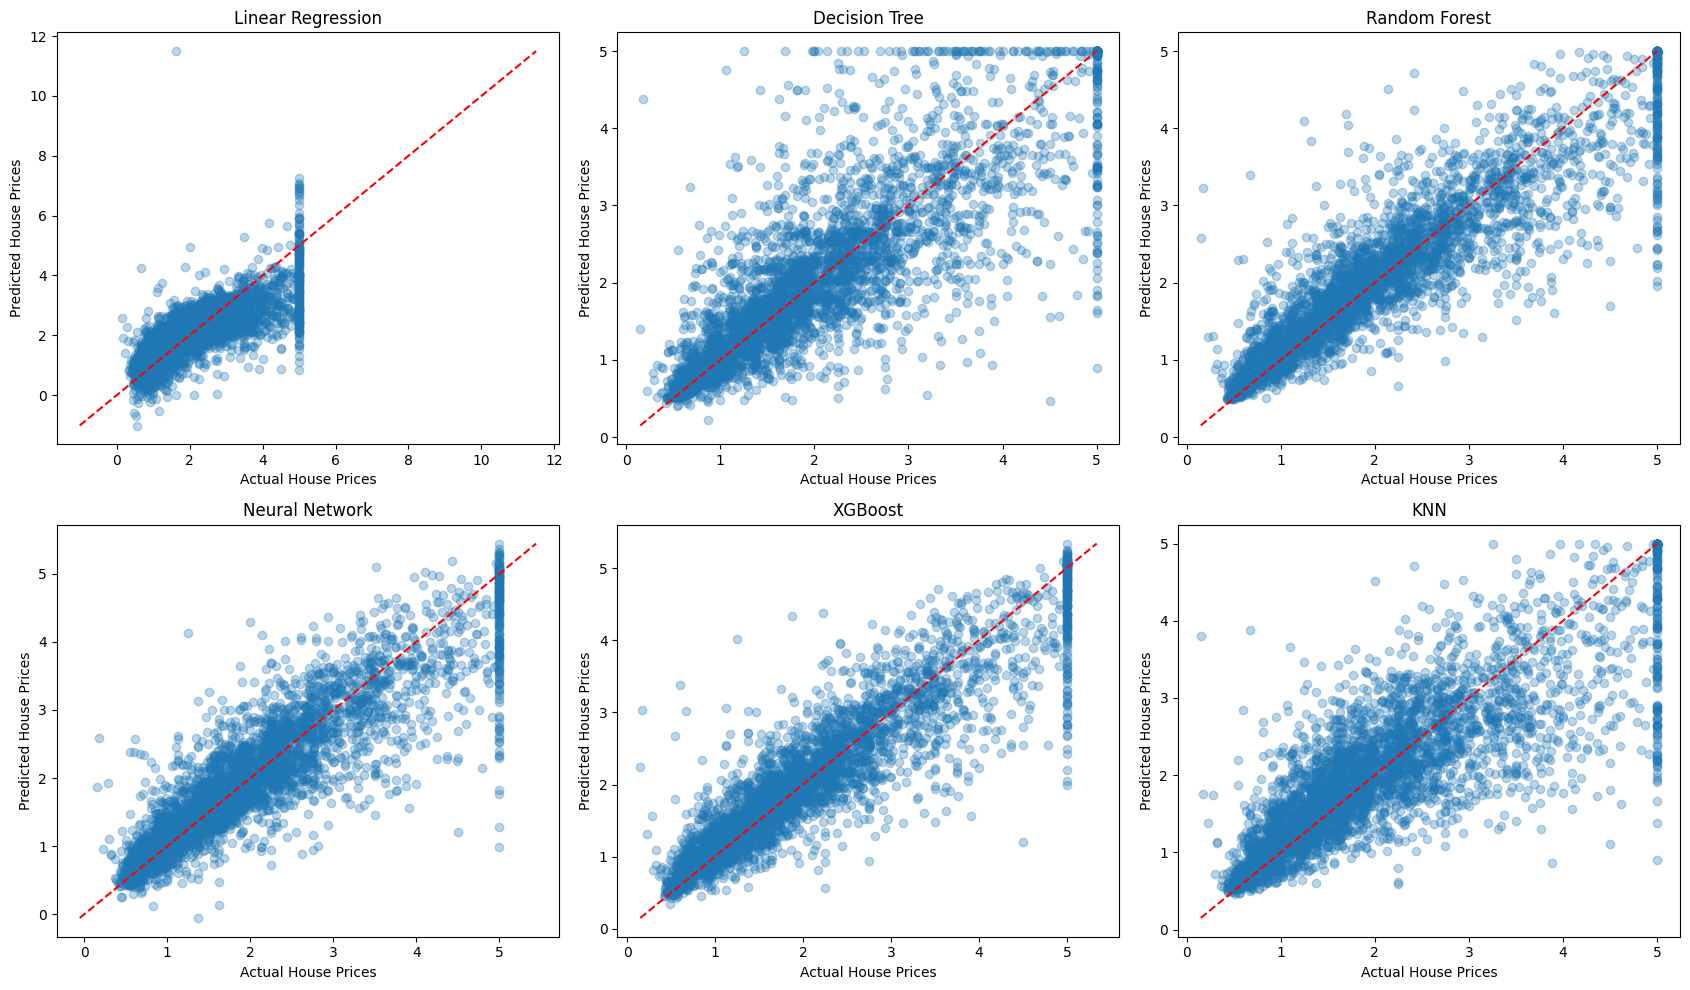

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, (name, pred) in zip(axes.flatten(), predictions.items()):

    ax.scatter(
        y_test,
        pred,
        alpha=0.3
    )

    # Perfect prediction reference line
    minimum = min(y_test.min(), pred.min())
    maximum = max(y_test.max(), pred.max())

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        'r--'
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Prices")
    ax.set_ylabel("Predicted House Prices")

plt.tight_layout()
plt.show()

In [ ]:
best_model = results_df.loc[
    results_df["R2 Score"].idxmax()
]

print("Best Performing Algorithm:")
print(best_model)

# Also identify lowest RMSE
lowest_rmse = results_df.loc[
    results_df["RMSE"].idxmin()
]

print("\nModel with Lowest RMSE:")
print(lowest_rmse)

Best Performing Algorithm:
Algorithm     XGBoost
MAE          0.315593
MSE          0.224536
RMSE         0.473853
R2 Score     0.828652
Name: 4, dtype: object

Model with Lowest RMSE:
Algorithm     XGBoost
MAE          0.315593
MSE          0.224536
RMSE         0.473853
R2 Score     0.828652
Name: 4, dtype: object
